# LE5 - Zentrale Aktoren & Aktor-Gruppen finden

This notebook analyzes network centrality measures to identify the most important actors in football networks:

1. **Degree Centrality**: Players/teams with most connections
2. **Betweenness Centrality**: Actors that bridge different parts of the network
3. **Closeness Centrality**: Actors with shortest paths to all others
4. **Eigenvector Centrality / PageRank**: Actors connected to other important actors
5. **Actor Groups**: k-cores, k-shells, and bridging nodes

We will analyze both pass networks (players) and match networks (teams).

In [1]:
# Import required libraries
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns


# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [2]:
from src.config import (
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR,
)

In [3]:
# General settings
warnings.filterwarnings('ignore')

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

In [4]:
# Load networks
print("=== Loading Networks ===\n")

# Pass Network (directed, weighted)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass_dir = nx.read_gexf(pass_network_path)
print(f"Pass Network (Germany): {G_pass_dir.number_of_nodes()} nodes, {G_pass_dir.number_of_edges()} edges")

# Convert to undirected for some centrality measures
G_pass = G_pass_dir.to_undirected()

# Match Network (directed)
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match_dir = nx.read_gexf(match_network_path)
print(f"Match Network (World Cup): {G_match_dir.number_of_nodes()} nodes, {G_match_dir.number_of_edges()} edges")

# Convert to undirected
G_match = G_match_dir.to_undirected()

# Unified Pass Network
unified_pass_path = PASS_NETWORKS_DIR / 'pass_network_unified.gexf'
if unified_pass_path.exists():
    G_unified_dir = nx.read_gexf(unified_pass_path)
    G_unified = G_unified_dir.to_undirected()
    print(f"Unified Pass Network: {G_unified.number_of_nodes()} nodes, {G_unified.number_of_edges()} edges")
else:
    G_unified = None
    print("Unified pass network not found")

print("\nNetworks loaded successfully!")

=== Loading Networks ===

Pass Network (Germany): 473 nodes, 8815 edges
Match Network (World Cup): 32 nodes, 126 edges
Unified Pass Network: 3029 nodes, 33273 edges

Networks loaded successfully!


## 1. Degree Centrality

**Degree Centrality** measures how many connections a node has. In undirected networks, it's simply the number of edges connected to a node. In directed networks, we distinguish:
- **In-degree**: number of incoming edges
- **Out-degree**: number of outgoing edges

For **weighted networks**, we use **strength** (weighted degree) instead:
- Sum of edge weights for all adjacent edges

### Theoretical Background

For an undirected network with adjacency matrix $A$:
$$C_D(i) = \sum_{j} A_{ij}$$

**Normalized Degree Centrality**:
$$C_D^{norm}(i) = \frac{C_D(i)}{n-1}$$

where $n$ is the number of nodes. This normalizes to $[0,1]$.

### Interpretation
- High degree centrality → node is well-connected (popular, influential)
- In pass networks: players who pass/receive frequently
- In match networks: teams that play against many different opponents

In [5]:
### 1.1 Degree Centrality - Pass Network (Undirected)

# Calculate degree centrality (normalized and unnormalized)
degree_cent = nx.degree_centrality(G_pass)
degree_raw = dict(G_pass.degree())

# Create DataFrame for analysis
df_degree_pass = pd.DataFrame({
    'Player': list(degree_cent.keys()),
    'Degree': [degree_raw[p] for p in degree_cent.keys()],
    'Degree_Centrality': list(degree_cent.values()),
})
df_degree_pass = df_degree_pass.sort_values('Degree', ascending=False)

print("=== Top 15 Players by Degree (Pass Network - Germany) ===\n")
print(df_degree_pass.head(15).to_string(index=False))
print(f"\nTotal players: {len(df_degree_pass)}")
print(f"Max degree: {df_degree_pass['Degree'].max()}")
print(f"Mean degree: {df_degree_pass['Degree'].mean():.2f}")
print(f"Median degree: {df_degree_pass['Degree'].median():.1f}")

=== Top 15 Players by Degree (Pass Network - Germany) ===

Player  Degree  Degree_Centrality
 15085      47           0.099576
284469      44           0.093220
 16094      43           0.091102
149389      42           0.088983
 14731      38           0.080508
105619      37           0.078390
 15771      36           0.076271
 16110      31           0.065678
356903      29           0.061441
224971      29           0.061441
272338      28           0.059322
127685      28           0.059322
 14734      28           0.059322
 15191      27           0.057203
 14917      27           0.057203

Total players: 473
Max degree: 47
Mean degree: 20.12
Median degree: 22.0


In [6]:
### 1.2 Degree Centrality with Weights (Strength)

# For weighted networks, we use "strength" (sum of edge weights)
# Get weighted degree (strength)
def calculate_strength(G):
    """Calculate weighted degree (strength) for each node"""
    strength = {}
    for node in G.nodes():
        s = 0
        for neighbor in G.neighbors(node):
            if 'weight' in G[node][neighbor]:
                s += float(G[node][neighbor]['weight'])
            else:
                s += 1
        strength[node] = s
    return strength

strength_pass = calculate_strength(G_pass)

df_strength_pass = pd.DataFrame({
    'Player': list(strength_pass.keys()),
    'Strength': list(strength_pass.values()),
    'Degree': [degree_raw[p] for p in strength_pass.keys()],
})
df_strength_pass = df_strength_pass.sort_values('Strength', ascending=False)

print("=== Top 15 Players by Strength (Weighted Degree) ===\n")
print(df_strength_pass.head(15).to_string(index=False))

# Compare degree vs strength
print(f"\nMean strength: {df_strength_pass['Strength'].mean():.2f}")
print(f"Max strength: {df_strength_pass['Strength'].max():.0f}")
print(f"Correlation degree-strength: {df_strength_pass['Degree'].corr(df_strength_pass['Strength']):.3f}")

=== Top 15 Players by Strength (Weighted Degree) ===

Player  Strength  Degree
 14778    1173.0      26
 14687    1142.0      27
134383    1121.0      24
 15806    1103.0      23
340646    1030.0      24
 14842     949.0      25
 14991     933.0      22
 14795     883.0      24
    77     827.0      23
 14718     820.0      25
 14803     820.0      21
  3416     772.0      25
 14716     766.0      22
  8309     763.0      20
 14838     744.0      23

Mean strength: 249.06
Max strength: 1173
Correlation degree-strength: 0.555


In [7]:
### 1.3 In-Degree and Out-Degree (Directed Pass Network)

# Use directed network
in_degree_cent = nx.in_degree_centrality(G_pass_dir)
out_degree_cent = nx.out_degree_centrality(G_pass_dir)

df_directed_degree = pd.DataFrame({
    'Player': list(in_degree_cent.keys()),
    'In_Degree_Cent': list(in_degree_cent.values()),
    'Out_Degree_Cent': list(out_degree_cent.values()),
    'In_Degree': [G_pass_dir.in_degree(p) for p in in_degree_cent.keys()],
    'Out_Degree': [G_pass_dir.out_degree(p) for p in in_degree_cent.keys()],
})

# Top receivers (in-degree)
print("=== Top 10 Players by In-Degree (Pass Receivers) ===\n")
df_in = df_directed_degree.sort_values('In_Degree', ascending=False)
print(df_in[['Player', 'In_Degree', 'In_Degree_Cent']].head(10).to_string(index=False))

# Top passers (out-degree)
print("\n=== Top 10 Players by Out-Degree (Pass Givers) ===\n")
df_out = df_directed_degree.sort_values('Out_Degree', ascending=False)
print(df_out[['Player', 'Out_Degree', 'Out_Degree_Cent']].head(10).to_string(index=False))

=== Top 10 Players by In-Degree (Pass Receivers) ===

Player  In_Degree  In_Degree_Cent
 15085         44        0.093220
 16094         42        0.088983
284469         41        0.086864
149389         41        0.086864
 14731         38        0.080508
105619         36        0.076271
 16110         30        0.063559
 15771         30        0.063559
224971         29        0.061441
356903         29        0.061441

=== Top 10 Players by Out-Degree (Pass Givers) ===

Player  Out_Degree  Out_Degree_Cent
 15085          45         0.095339
284469          41         0.086864
149389          40         0.084746
 16094          35         0.074153
105619          35         0.074153
 15771          34         0.072034
 14731          32         0.067797
356903          29         0.061441
 16110          29         0.061441
127685          28         0.059322


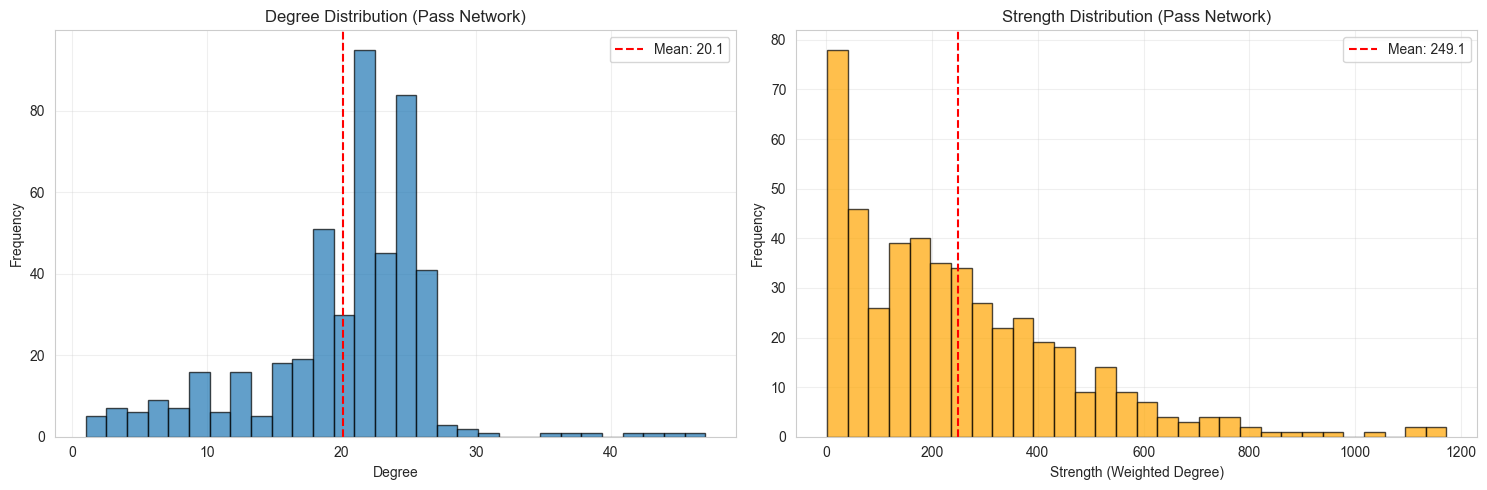

Figure saved: reports/figures/LE5/degree_distribution.png


In [8]:
### 1.4 Visualization - Degree Distribution

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Degree distribution
axes[0].hist(df_degree_pass['Degree'], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Degree Distribution (Pass Network)')
axes[0].axvline(df_degree_pass['Degree'].mean(), color='red', linestyle='--', label=f'Mean: {df_degree_pass["Degree"].mean():.1f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Strength distribution
axes[1].hist(df_strength_pass['Strength'], bins=30, edgecolor='black', alpha=0.7, color='orange')
axes[1].set_xlabel('Strength (Weighted Degree)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Strength Distribution (Pass Network)')
axes[1].axvline(df_strength_pass['Strength'].mean(), color='red', linestyle='--', label=f'Mean: {df_strength_pass["Strength"].mean():.1f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'degree_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/degree_distribution.png")

## 2. Betweenness Centrality

**Betweenness Centrality** measures how often a node lies on the shortest paths between other nodes. Nodes with high betweenness act as bridges or brokers in the network.

### Theoretical Background

$$C_B(i) = \sum_{s \neq i \neq t} \frac{\sigma_{st}(i)}{\sigma_{st}}$$

where:
- $\sigma_{st}$ = total number of shortest paths from $s$ to $t$
- $\sigma_{st}(i)$ = number of those paths passing through node $i$

**Normalized Betweenness**:
$$C_B^{norm}(i) = \frac{2 \cdot C_B(i)}{(n-1)(n-2)}$$

### Interpretation
- High betweenness → node controls information flow, acts as bridge
- Removal of high-betweenness nodes can fragment the network
- In pass networks: players who connect different parts of the team
- In match networks: teams that bridge different competitive groups

In [9]:
### 2.1 Betweenness Centrality - Pass Network

# Calculate betweenness centrality (this can be computationally expensive)
print("Calculating betweenness centrality (this may take a moment)...")

# Get largest connected component
components = list(nx.connected_components(G_pass))
largest_cc = max(components, key=len)
G_pass_cc = G_pass.subgraph(largest_cc).copy()

print(f"Using largest connected component: {len(largest_cc)} / {G_pass.number_of_nodes()} nodes")

betweenness_cent = nx.betweenness_centrality(G_pass_cc, normalized=True)

df_betweenness = pd.DataFrame({
    'Player': list(betweenness_cent.keys()),
    'Betweenness_Centrality': list(betweenness_cent.values()),
})
df_betweenness = df_betweenness.sort_values('Betweenness_Centrality', ascending=False)

print("\n=== Top 15 Players by Betweenness Centrality ===\n")
print(df_betweenness.head(15).to_string(index=False))

print(f"\nMean betweenness: {df_betweenness['Betweenness_Centrality'].mean():.6f}")
print(f"Max betweenness: {df_betweenness['Betweenness_Centrality'].max():.6f}")
print(f"Players with zero betweenness: {(df_betweenness['Betweenness_Centrality'] == 0).sum()}")

Calculating betweenness centrality (this may take a moment)...
Using largest connected component: 283 / 473 nodes

=== Top 15 Players by Betweenness Centrality ===

Player  Betweenness_Centrality
347366                0.498145
 15085                0.397508
149389                0.326156
272363                0.311169
391441                0.288160
105619                0.270228
 14731                0.195094
284469                0.192020
 16094                0.190856
 14778                0.183059
224971                0.167993
 15771                0.156296
 16110                0.144452
356906                0.130786
  3416                0.034589

Mean betweenness: 0.015929
Max betweenness: 0.498145
Players with zero betweenness: 30


In [10]:
### 2.2 Comparison: Degree vs Betweenness

# Merge degree and betweenness data
df_comparison = df_degree_pass.merge(df_betweenness, on='Player', how='outer')
df_comparison = df_comparison.fillna(0)
df_comparison = df_comparison.sort_values('Betweenness_Centrality', ascending=False)

print("=== Players with Highest Betweenness (comparing with Degree) ===\n")
print(df_comparison[['Player', 'Degree', 'Degree_Centrality', 'Betweenness_Centrality']].head(15).to_string(index=False))

# Calculate correlation
corr = df_comparison['Degree_Centrality'].corr(df_comparison['Betweenness_Centrality'])
print(f"\nCorrelation Degree-Betweenness: {corr:.3f}")

# Find players with high betweenness but low degree (bridging nodes)
df_comparison['Degree_Rank'] = df_comparison['Degree'].rank(ascending=False)
df_comparison['Betweenness_Rank'] = df_comparison['Betweenness_Centrality'].rank(ascending=False)
df_comparison['Rank_Diff'] = df_comparison['Degree_Rank'] - df_comparison['Betweenness_Rank']

print("\n=== Bridging Nodes: High Betweenness, Relatively Low Degree ===")
bridging_candidates = df_comparison[
    (df_comparison['Betweenness_Rank'] <= 30) & 
    (df_comparison['Rank_Diff'] > 20)
].sort_values('Betweenness_Centrality', ascending=False)
print(bridging_candidates[['Player', 'Degree', 'Betweenness_Centrality', 'Degree_Rank', 'Betweenness_Rank']].head(10).to_string(index=False))

=== Players with Highest Betweenness (comparing with Degree) ===

Player  Degree  Degree_Centrality  Betweenness_Centrality
347366      17           0.036017                0.498145
 15085      47           0.099576                0.397508
149389      42           0.088983                0.326156
272363      27           0.057203                0.311169
391441      26           0.055085                0.288160
105619      37           0.078390                0.270228
 14731      38           0.080508                0.195094
284469      44           0.093220                0.192020
 16094      43           0.091102                0.190856
 14778      26           0.055085                0.183059
224971      29           0.061441                0.167993
 15771      36           0.076271                0.156296
 16110      31           0.065678                0.144452
356906      17           0.036017                0.130786
  3416      25           0.052966                0.034589

Corre

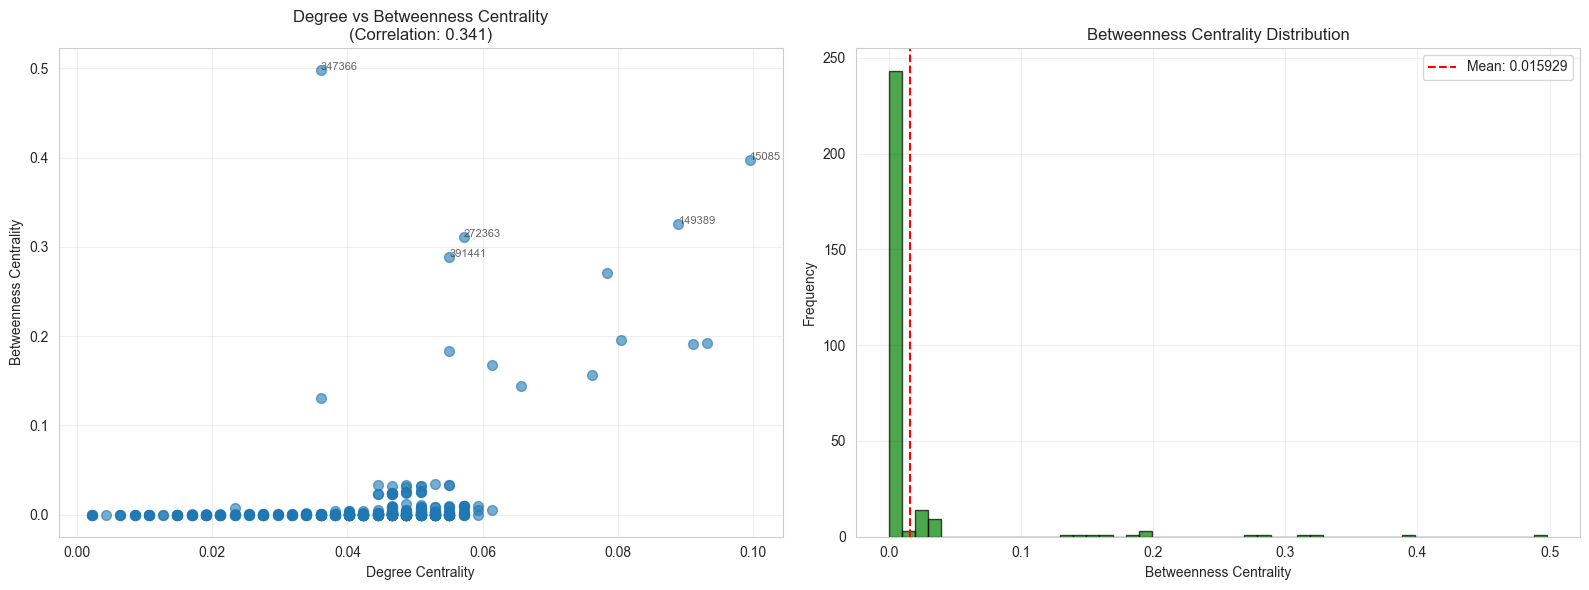

Figure saved: reports/figures/LE5/betweenness_analysis.png


In [11]:
### 2.3 Visualization - Degree vs Betweenness Scatter

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot
axes[0].scatter(df_comparison['Degree_Centrality'], 
                df_comparison['Betweenness_Centrality'],
                alpha=0.6, s=50)
axes[0].set_xlabel('Degree Centrality')
axes[0].set_ylabel('Betweenness Centrality')
axes[0].set_title(f'Degree vs Betweenness Centrality\n(Correlation: {corr:.3f})')
axes[0].grid(True, alpha=0.3)

# Annotate top players
top_n = 5
top_betweenness = df_comparison.nlargest(top_n, 'Betweenness_Centrality')
for _, row in top_betweenness.iterrows():
    axes[0].annotate(row['Player'][:15], 
                     (row['Degree_Centrality'], row['Betweenness_Centrality']),
                     fontsize=8, alpha=0.7)

# Betweenness distribution
axes[1].hist(df_betweenness['Betweenness_Centrality'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[1].set_xlabel('Betweenness Centrality')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Betweenness Centrality Distribution')
axes[1].axvline(df_betweenness['Betweenness_Centrality'].mean(), 
                color='red', linestyle='--', 
                label=f'Mean: {df_betweenness["Betweenness_Centrality"].mean():.6f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'betweenness_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/betweenness_analysis.png")

## 3. Closeness Centrality

**Closeness Centrality** measures how close a node is to all other nodes in the network. It's based on the average shortest path length to all other reachable nodes.

### Theoretical Background

$$C_C(i) = \frac{n-1}{\sum_{j \neq i} d(i,j)}$$

where $d(i,j)$ is the shortest path distance from $i$ to $j$.

**Normalized Closeness** is already in $[0,1]$ range.

### Interpretation
- High closeness → node can quickly reach all others
- In pass networks: players who are well-integrated in the team's passing structure
- Requires connected components (or disconnected: uses harmonic mean)
- Only meaningful in connected graphs or with adaptations for disconnected graphs

**Note**: NetworkX uses **harmonic centrality** for disconnected graphs, which uses the reciprocal of distances.

In [12]:
### 3.1 Closeness Centrality - Pass Network

# Calculate closeness on largest connected component
closeness_cent = nx.closeness_centrality(G_pass_cc)

df_closeness = pd.DataFrame({
    'Player': list(closeness_cent.keys()),
    'Closeness_Centrality': list(closeness_cent.values()),
})
df_closeness = df_closeness.sort_values('Closeness_Centrality', ascending=False)

print("=== Top 15 Players by Closeness Centrality ===\n")
print(df_closeness.head(15).to_string(index=False))

print(f"\nMean closeness: {df_closeness['Closeness_Centrality'].mean():.6f}")
print(f"Max closeness: {df_closeness['Closeness_Centrality'].max():.6f}")
print(f"Min closeness: {df_closeness['Closeness_Centrality'].min():.6f}")

=== Top 15 Players by Closeness Centrality ===

Player  Closeness_Centrality
347366              0.264292
235597              0.260870
 15032              0.260870
 70139              0.260870
 99410              0.260628
413737              0.260628
 14754              0.260628
349099              0.260388
 15798              0.260388
345707              0.260388
 14715              0.260388
328131              0.260388
 14885              0.260388
233910              0.260148
 14845              0.260148

Mean closeness: 0.189221
Max closeness: 0.264292
Min closeness: 0.119949


## 4. Eigenvector Centrality and PageRank

**Eigenvector Centrality** measures the influence of a node based on the quality of its connections. A node has high eigenvector centrality if it's connected to other high-centrality nodes.

### Theoretical Background

Eigenvector centrality $\mathbf{x}$ satisfies:
$$\mathbf{x} = \lambda \mathbf{A} \mathbf{x}$$

where $\lambda$ is the largest eigenvalue of adjacency matrix $\mathbf{A}$.

**PageRank** is a variant that adds a damping factor $\alpha$ (typically 0.85):
$$PR(i) = \frac{1-\alpha}{n} + \alpha \sum_{j \to i} \frac{PR(j)}{deg^{out}(j)}$$

### Interpretation
- **Eigenvector**: being connected to important nodes makes you important
- **PageRank**: accounts for directed networks, includes random walk probability
- In pass networks: players connected to key players
- PageRank better for directed networks (pass direction matters)

In [13]:
### 4.1 Eigenvector Centrality - Undirected Pass Network

try:
    eigenvector_cent = nx.eigenvector_centrality(G_pass_cc, max_iter=500)
    
    df_eigenvector = pd.DataFrame({
        'Player': list(eigenvector_cent.keys()),
        'Eigenvector_Centrality': list(eigenvector_cent.values()),
    })
    df_eigenvector = df_eigenvector.sort_values('Eigenvector_Centrality', ascending=False)
    
    print("=== Top 15 Players by Eigenvector Centrality ===\n")
    print(df_eigenvector.head(15).to_string(index=False))
    
    print(f"\nMean eigenvector: {df_eigenvector['Eigenvector_Centrality'].mean():.6f}")
    print(f"Max eigenvector: {df_eigenvector['Eigenvector_Centrality'].max():.6f}")
    
except nx.PowerIterationFailedConvergence:
    print("Eigenvector centrality did not converge. Using eigenvector_centrality_numpy...")
    eigenvector_cent = nx.eigenvector_centrality_numpy(G_pass_cc)
    
    df_eigenvector = pd.DataFrame({
        'Player': list(eigenvector_cent.keys()),
        'Eigenvector_Centrality': list(eigenvector_cent.values()),
    })
    df_eigenvector = df_eigenvector.sort_values('Eigenvector_Centrality', ascending=False)
    
    print("=== Top 15 Players by Eigenvector Centrality (numpy) ===\n")
    print(df_eigenvector.head(15).to_string(index=False))

=== Top 15 Players by Eigenvector Centrality ===

Player  Eigenvector_Centrality
284469                0.197655
 16094                0.191433
 14731                0.172599
 14938                0.139069
 14917                0.139069
 15191                0.139069
 15129                0.138225
 15795                0.138225
134708                0.135476
 25861                0.135460
 15775                0.134137
343685                0.132808
228639                0.132707
149091                0.131965
337682                0.129730

Mean eigenvector: 0.034014
Max eigenvector: 0.197655


In [14]:
### 4.2 PageRank - Directed Pass Network

# Get largest strongly connected component for directed network
# Or use weakly connected for PageRank (more lenient)
components_dir = list(nx.weakly_connected_components(G_pass_dir))
largest_cc_dir = max(components_dir, key=len)
G_pass_dir_cc = G_pass_dir.subgraph(largest_cc_dir).copy()

print(f"Largest weakly connected component: {len(largest_cc_dir)} / {G_pass_dir.number_of_nodes()} nodes\n")

pagerank = nx.pagerank(G_pass_dir_cc, alpha=0.85)

df_pagerank = pd.DataFrame({
    'Player': list(pagerank.keys()),
    'PageRank': list(pagerank.values()),
})
df_pagerank = df_pagerank.sort_values('PageRank', ascending=False)

print("=== Top 15 Players by PageRank ===\n")
print(df_pagerank.head(15).to_string(index=False))

print(f"\nMean PageRank: {df_pagerank['PageRank'].mean():.6f}")
print(f"Max PageRank: {df_pagerank['PageRank'].max():.6f}")

Largest weakly connected component: 283 / 473 nodes

=== Top 15 Players by PageRank ===

Player  PageRank
340646  0.010752
 14795  0.010266
 14778  0.010178
235597  0.010002
  8309  0.009718
 11095  0.009677
 15775  0.009675
 14687  0.009465
 14842  0.009432
    77  0.008977
 16843  0.008681
228768  0.008419
 15937  0.008146
 14917  0.008054
 15125  0.007896

Mean PageRank: 0.003534
Max PageRank: 0.010752


In [15]:
### 4.3 Comparison of All Centrality Measures

# Merge all centrality measures
df_all_centrality = df_degree_pass[['Player', 'Degree', 'Degree_Centrality']].copy()
df_all_centrality = df_all_centrality.merge(df_betweenness[['Player', 'Betweenness_Centrality']], on='Player', how='outer')
df_all_centrality = df_all_centrality.merge(df_closeness[['Player', 'Closeness_Centrality']], on='Player', how='outer')
df_all_centrality = df_all_centrality.merge(df_eigenvector[['Player', 'Eigenvector_Centrality']], on='Player', how='outer')
df_all_centrality = df_all_centrality.merge(df_pagerank[['Player', 'PageRank']], on='Player', how='outer')
df_all_centrality = df_all_centrality.fillna(0)

# Create composite score (simple average of normalized ranks)
for col in ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
            'Eigenvector_Centrality', 'PageRank']:
    if col in df_all_centrality.columns:
        df_all_centrality[f'{col}_rank'] = df_all_centrality[col].rank(ascending=False)

# Compute average rank
rank_cols = [c for c in df_all_centrality.columns if c.endswith('_rank')]
df_all_centrality['Avg_Rank'] = df_all_centrality[rank_cols].mean(axis=1)
df_all_centrality = df_all_centrality.sort_values('Avg_Rank')

print("=== Top 15 Players by Average Rank (All Centrality Measures) ===\n")
display_cols = ['Player', 'Degree', 'Degree_Centrality', 'Betweenness_Centrality', 
                'Closeness_Centrality', 'Eigenvector_Centrality', 'PageRank', 'Avg_Rank']
print(df_all_centrality[display_cols].head(15).to_string(index=False))

# Correlation matrix
centrality_cols = ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
                   'Eigenvector_Centrality', 'PageRank']
corr_matrix = df_all_centrality[centrality_cols].corr()

print("\n=== Correlation Matrix of Centrality Measures ===\n")
print(corr_matrix.round(3))

=== Top 15 Players by Average Rank (All Centrality Measures) ===

Player  Degree  Degree_Centrality  Betweenness_Centrality  Closeness_Centrality  Eigenvector_Centrality  PageRank  Avg_Rank
284469      44           0.093220                0.192020              0.241232                0.197655  0.004679      21.0
 14731      38           0.080508                0.195094              0.257534                0.172599  0.004637      21.7
 14917      27           0.057203                0.009078              0.231717                0.139069  0.008054      22.3
 14938      27           0.057203                0.009078              0.231717                0.139069  0.006537      25.1
 15775      26           0.055085                0.009461              0.231527                0.134137  0.009675      26.6
 15795      27           0.057203                0.009609              0.231717                0.138225  0.005425      29.3
 16094      43           0.091102                0.190856         

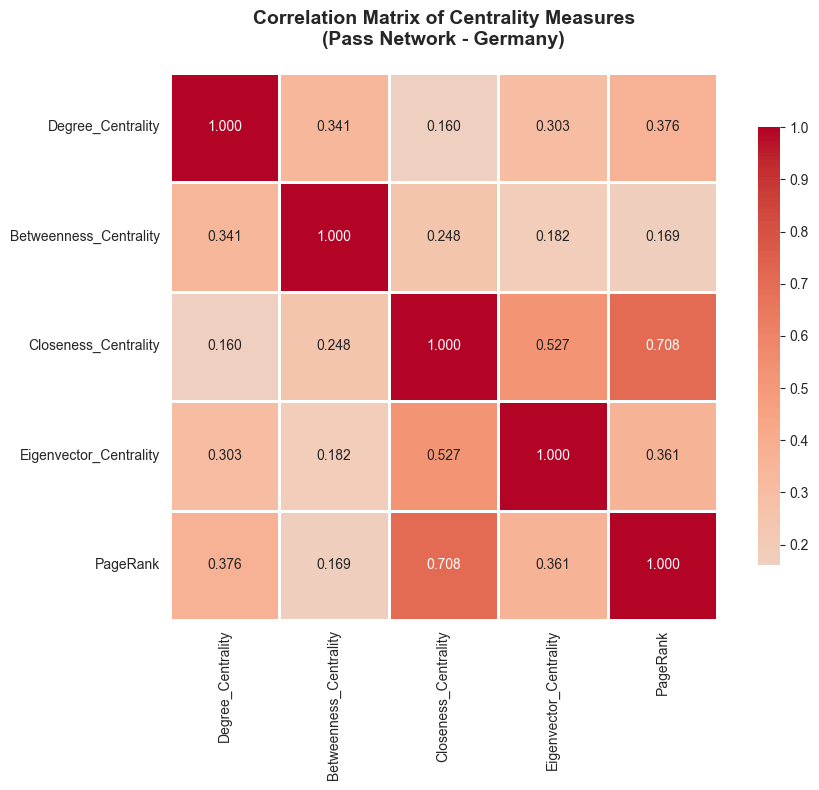

Figure saved: reports/figures/LE5/centrality_correlation.png


In [16]:
### 4.4 Visualization - Centrality Correlation Heatmap

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, 
            cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title('Correlation Matrix of Centrality Measures\n(Pass Network - Germany)', 
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'centrality_correlation.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/centrality_correlation.png")

## 5. Group-Level Analysis: k-Core and k-Shell

**k-Core**: A maximal subgraph where every node has degree at least $k$ within that subgraph.

**k-Shell**: Nodes that belong to the $k$-core but not to the $(k+1)$-core.

**Core Number**: The highest $k$ for which a node belongs to a $k$-core.

### Interpretation
- **High core number** → node is in a densely connected group
- k-cores reveal hierarchical structure of connectivity
- Core decomposition is useful for finding cohesive subgroups
- In pass networks: identifies groups of players with dense passing connections

In [17]:
### 5.1 k-Core Decomposition

# Compute core numbers
core_numbers = nx.core_number(G_pass_cc)

df_cores = pd.DataFrame({
    'Player': list(core_numbers.keys()),
    'Core_Number': list(core_numbers.values()),
})
df_cores = df_cores.sort_values('Core_Number', ascending=False)

print("=== Core Number Statistics ===")
print(f"Max core number (k-max): {df_cores['Core_Number'].max()}")
print(f"Mean core number: {df_cores['Core_Number'].mean():.2f}")
print(f"Median core number: {df_cores['Core_Number'].median():.0f}")

# Distribution of core numbers
core_dist = df_cores['Core_Number'].value_counts().sort_index(ascending=False)
print("\n=== Core Number Distribution ===")
for k, count in core_dist.head(10).items():
    print(f"k={k}: {count} players")

# Players in highest core
max_core = df_cores['Core_Number'].max()
highest_core_players = df_cores[df_cores['Core_Number'] == max_core]
print(f"\n=== Players in Highest Core (k={max_core}) ===")
print(f"Number of players: {len(highest_core_players)}")
print("\nPlayers:")
print(highest_core_players['Player'].to_string(index=False))

=== Core Number Statistics ===
Max core number (k-max): 20
Mean core number: 16.25
Median core number: 18

=== Core Number Distribution ===
k=20: 24 players
k=19: 63 players
k=18: 58 players
k=17: 25 players
k=16: 42 players
k=15: 27 players
k=14: 2 players
k=13: 3 players
k=12: 2 players
k=11: 7 players

=== Players in Highest Core (k=20) ===
Number of players: 24

Players:
272338
 18669
 16094
 91519
263490
 20680
356903
 16843
 15039
127685
 15122
 94831
356928
 14863
 15278
 15317
 15253
275384
 15194
 15265
 15543
279734
 14707
284524


In [18]:
### 5.2 Core Numbers vs Other Centrality Measures

# Merge core numbers with centrality data
df_with_cores = df_all_centrality.merge(df_cores, on='Player', how='left')
df_with_cores['Core_Number'] = df_with_cores['Core_Number'].fillna(0)

# Correlations
print("=== Correlation: Core Number vs Centrality Measures ===\n")
for measure in ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
                'Eigenvector_Centrality', 'PageRank']:
    corr = df_with_cores['Core_Number'].corr(df_with_cores[measure])
    print(f"{measure:30s}: {corr:.3f}")

# Top players by core number and degree
print("\n=== Top 20 Players by Core Number (with Degree) ===\n")
df_display = df_with_cores.sort_values('Core_Number', ascending=False)
print(df_display[['Player', 'Core_Number', 'Degree', 'Degree_Centrality', 'Betweenness_Centrality']].head(20).to_string(index=False))

=== Correlation: Core Number vs Centrality Measures ===

Degree_Centrality             : 0.295
Betweenness_Centrality        : 0.199
Closeness_Centrality          : 0.939
Eigenvector_Centrality        : 0.475
PageRank                      : 0.782

=== Top 20 Players by Core Number (with Degree) ===

Player  Core_Number  Degree  Degree_Centrality  Betweenness_Centrality
272338         20.0      28           0.059322                0.004736
275384         20.0      27           0.057203                0.003234
 20680         20.0      26           0.055085                0.001836
 16843         20.0      26           0.055085                0.002126
356903         20.0      29           0.061441                0.005275
 15253         20.0      27           0.057203                0.003832
127685         20.0      28           0.059322                0.009787
356928         20.0      24           0.050847                0.001936
 15543         20.0      24           0.050847              

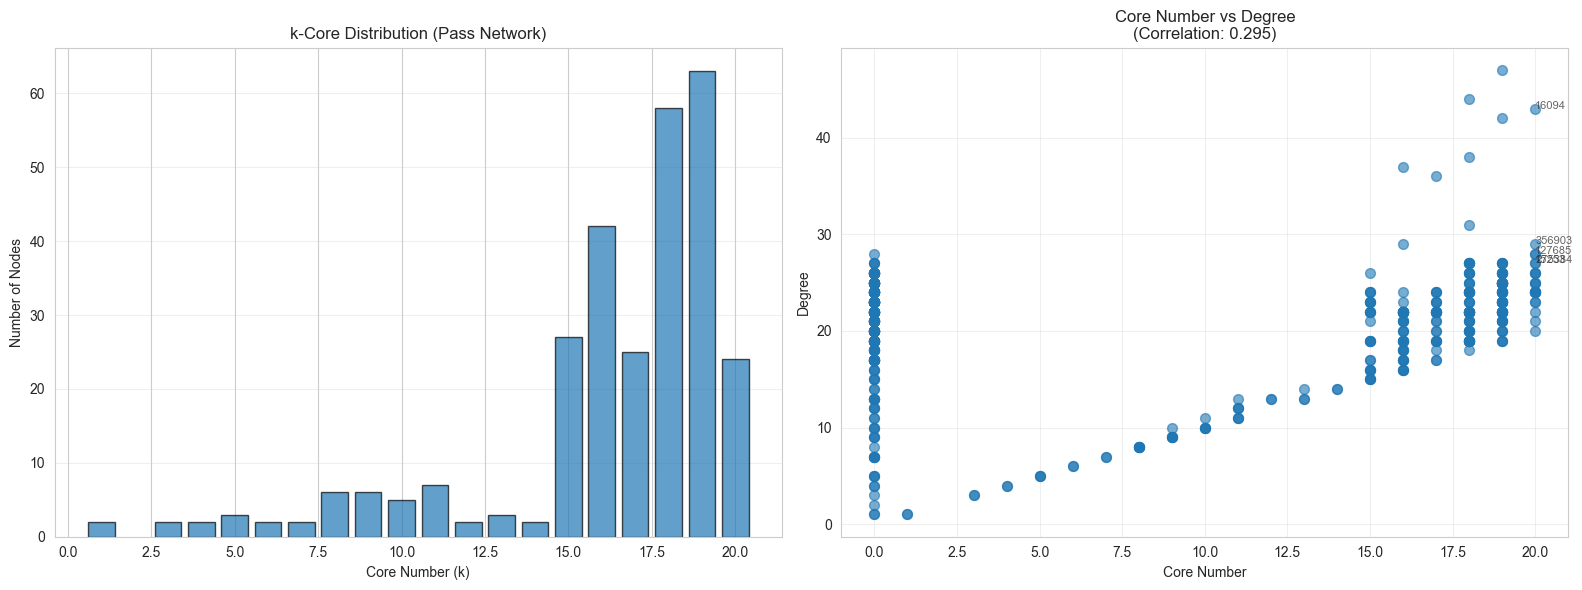

Figure saved: reports/figures/LE5/kcore_analysis.png


In [19]:
### 5.3 Visualization - Core Number Distribution and Scatter

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Core number distribution
axes[0].bar(core_dist.index, core_dist.values, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Core Number (k)')
axes[0].set_ylabel('Number of Nodes')
axes[0].set_title('k-Core Distribution (Pass Network)')
axes[0].grid(True, alpha=0.3, axis='y')

# Core number vs Degree scatter
axes[1].scatter(df_with_cores['Core_Number'], df_with_cores['Degree'], alpha=0.6, s=50)
axes[1].set_xlabel('Core Number')
axes[1].set_ylabel('Degree')
axes[1].set_title(f'Core Number vs Degree\n(Correlation: {df_with_cores["Core_Number"].corr(df_with_cores["Degree"]):.3f})')
axes[1].grid(True, alpha=0.3)

# Annotate some high-core players
top_core = df_with_cores.nlargest(5, 'Core_Number')
for _, row in top_core.iterrows():
    if pd.notna(row['Player']) and pd.notna(row['Core_Number']) and pd.notna(row['Degree']):
        axes[1].annotate(row['Player'][:15], 
                        (row['Core_Number'], row['Degree']),
                        fontsize=8, alpha=0.7)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'kcore_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved: reports/figures/LE5/kcore_analysis.png")

## 6. Centrality Analysis on Match Network (Teams)

Now we apply the same centrality measures to the **match network** (World Cup), where nodes are teams and edges represent matches.

In [20]:
### 6.1 Match Network - All Centrality Measures

# Get largest component
components_match = list(nx.connected_components(G_match))
largest_cc_match = max(components_match, key=len)
G_match_cc = G_match.subgraph(largest_cc_match).copy()

print(f"Match Network - Largest CC: {len(largest_cc_match)} / {G_match.number_of_nodes()} teams\n")

# Calculate all centrality measures
degree_cent_match = nx.degree_centrality(G_match_cc)
betweenness_cent_match = nx.betweenness_centrality(G_match_cc)
closeness_cent_match = nx.closeness_centrality(G_match_cc)

try:
    eigenvector_cent_match = nx.eigenvector_centrality(G_match_cc, max_iter=500)
except (nx.PowerIterationFailedConvergence, nx.NetworkXError):
    eigenvector_cent_match = nx.eigenvector_centrality_numpy(G_match_cc)

# For directed network
components_match_dir = list(nx.weakly_connected_components(G_match_dir))
largest_cc_match_dir = max(components_match_dir, key=len)
G_match_dir_cc = G_match_dir.subgraph(largest_cc_match_dir).copy()
pagerank_match = nx.pagerank(G_match_dir_cc, alpha=0.85)

# Create dataframe
df_match_centrality = pd.DataFrame({
    'Team': list(degree_cent_match.keys()),
    'Degree_Centrality': [degree_cent_match[t] for t in degree_cent_match.keys()],
    'Betweenness_Centrality': [betweenness_cent_match[t] for t in degree_cent_match.keys()],
    'Closeness_Centrality': [closeness_cent_match[t] for t in degree_cent_match.keys()],
    'Eigenvector_Centrality': [eigenvector_cent_match[t] for t in degree_cent_match.keys()],
})

# Add PageRank
df_pagerank_match = pd.DataFrame({
    'Team': list(pagerank_match.keys()),
    'PageRank': list(pagerank_match.values())
})
df_match_centrality = df_match_centrality.merge(df_pagerank_match, on='Team', how='left')

# Calculate average rank
for col in ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
            'Eigenvector_Centrality', 'PageRank']:
    df_match_centrality[f'{col}_rank'] = df_match_centrality[col].rank(ascending=False)

rank_cols_match = [c for c in df_match_centrality.columns if c.endswith('_rank')]
df_match_centrality['Avg_Rank'] = df_match_centrality[rank_cols_match].mean(axis=1)
df_match_centrality = df_match_centrality.sort_values('Avg_Rank')

print("=== Top 15 Teams by Average Centrality Rank (World Cup) ===\n")
display_cols_match = ['Team', 'Degree_Centrality', 'Betweenness_Centrality', 
                      'Closeness_Centrality', 'Eigenvector_Centrality', 'PageRank', 'Avg_Rank']
print(df_match_centrality[display_cols_match].head(15).to_string(index=False))

Match Network - Largest CC: 32 / 32 teams

=== Top 15 Teams by Average Centrality Rank (World Cup) ===

 Team  Degree_Centrality  Betweenness_Centrality  Closeness_Centrality  Eigenvector_Centrality  PageRank  Avg_Rank
 4418           0.225806                0.325842              0.442857                0.392332  0.036391       3.4
 9598           0.225806                0.325842              0.442857                0.392332  0.035941       3.6
 2413           0.193548                0.324767              0.442857                0.269910  0.034243       5.4
14358           0.161290                0.174229              0.360465                0.205881  0.042112       5.8
 5629           0.193548                0.324767              0.442857                0.269910  0.028679       6.4
 7047           0.161290                0.164516              0.356322                0.121991  0.041349       8.6
12274           0.129032                0.013620              0.352273                0.258

=== Correlation Matrix - Match Network ===

                        Degree_Centrality  Betweenness_Centrality  \
Degree_Centrality                   1.000                   0.963   
Betweenness_Centrality              0.963                   1.000   
Closeness_Centrality                0.857                   0.862   
Eigenvector_Centrality              0.744                   0.711   
PageRank                            0.085                   0.039   

                        Closeness_Centrality  Eigenvector_Centrality  PageRank  
Degree_Centrality                      0.857                   0.744     0.085  
Betweenness_Centrality                 0.862                   0.711     0.039  
Closeness_Centrality                   1.000                   0.894     0.030  
Eigenvector_Centrality                 0.894                   1.000    -0.036  
PageRank                               0.030                  -0.036     1.000  


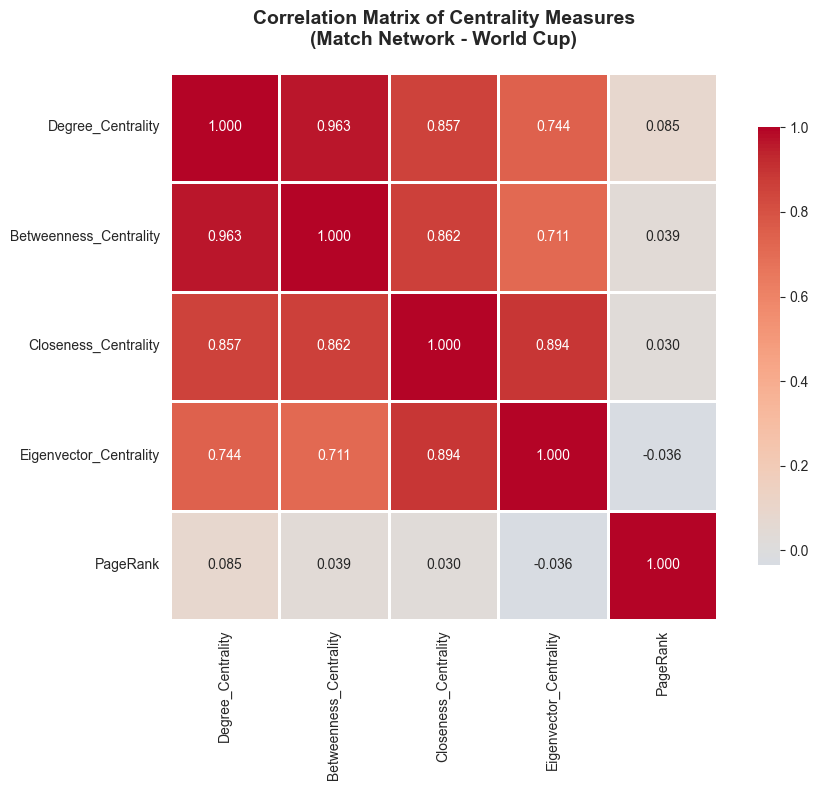


Figure saved: reports/figures/LE5/centrality_correlation_match.png


In [21]:
### 6.2 Match Network - Correlation Analysis

# Correlation matrix for match network
centrality_cols_match = ['Degree_Centrality', 'Betweenness_Centrality', 'Closeness_Centrality', 
                         'Eigenvector_Centrality', 'PageRank']
corr_matrix_match = df_match_centrality[centrality_cols_match].corr()

print("=== Correlation Matrix - Match Network ===\n")
print(corr_matrix_match.round(3))

# Visualization
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(corr_matrix_match, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, 
            cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title('Correlation Matrix of Centrality Measures\n(Match Network - World Cup)', 
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE5' / 'centrality_correlation_match.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("\nFigure saved: reports/figures/LE5/centrality_correlation_match.png")

## 7. Summary and Key Findings

Let's summarize the most central actors identified across all measures.

In [22]:
### 7.1 Top Central Players Summary

print("="*80)
print("SUMMARY: TOP CENTRAL ACTORS")
print("="*80)

print("\n### PASS NETWORK (Germany) - Top 5 by Each Measure ###\n")

print("Degree Centrality (Most Connected):")
for i, row in df_degree_pass.head(5).iterrows():
    print(f"  {row['Player']:40s} - Degree: {row['Degree']:.0f}")

print("\nBetweenness Centrality (Best Bridges):")
for i, row in df_betweenness.head(5).iterrows():
    print(f"  {row['Player']:40s} - Betweenness: {row['Betweenness_Centrality']:.6f}")

print("\nCloseness Centrality (Most Accessible):")
for i, row in df_closeness.head(5).iterrows():
    print(f"  {row['Player']:40s} - Closeness: {row['Closeness_Centrality']:.6f}")

print("\nPageRank (Most Influential):")
for i, row in df_pagerank.head(5).iterrows():
    print(f"  {row['Player']:40s} - PageRank: {row['PageRank']:.6f}")

print("\nCore Number (Most Dense Connections):")
for i, row in df_cores.head(5).iterrows():
    print(f"  {row['Player']:40s} - Core: {row['Core_Number']:.0f}")

print("\n" + "="*80)
print("\n### MATCH NETWORK (World Cup) - Top 5 Overall ###\n")

for i, row in df_match_centrality.head(5).iterrows():
    print(f"{row['Team']:30s} - Avg Rank: {row['Avg_Rank']:.2f}")

SUMMARY: TOP CENTRAL ACTORS

### PASS NETWORK (Germany) - Top 5 by Each Measure ###

Degree Centrality (Most Connected):
  15085                                    - Degree: 47
  284469                                   - Degree: 44
  16094                                    - Degree: 43
  149389                                   - Degree: 42
  14731                                    - Degree: 38

Betweenness Centrality (Best Bridges):
  347366                                   - Betweenness: 0.498145
  15085                                    - Betweenness: 0.397508
  149389                                   - Betweenness: 0.326156
  272363                                   - Betweenness: 0.311169
  391441                                   - Betweenness: 0.288160

Closeness Centrality (Most Accessible):
  347366                                   - Closeness: 0.264292
  235597                                   - Closeness: 0.260870
  15032                                    - Closenes

In [23]:
### 7.2 Export Results for LaTeX

# Save pass network centrality results
df_with_cores.to_csv(project_root / 'reports' / 'figures' / 'LE5' / 'player_centrality.csv', index=False)
print("Saved: reports/figures/LE5/player_centrality.csv")

# Save match network centrality results
df_match_centrality.to_csv(project_root / 'reports' / 'figures' / 'LE5' / 'team_centrality.csv', index=False)
print("Saved: reports/figures/LE5/team_centrality.csv")

# Create LaTeX table for top players
top_10_overall = df_with_cores.nsmallest(10, 'Avg_Rank')
latex_table = top_10_overall[['Player', 'Degree', 'Betweenness_Centrality', 'Closeness_Centrality', 
                               'PageRank', 'Core_Number']].copy()

# Round values
latex_table['Betweenness_Centrality'] = latex_table['Betweenness_Centrality'].round(4)
latex_table['Closeness_Centrality'] = latex_table['Closeness_Centrality'].round(4)
latex_table['PageRank'] = latex_table['PageRank'].round(4)

with open(project_root / 'reports' / 'figures' / 'LE5' / 'top_players_table.tex', 'w') as f:
    f.write(latex_table.to_latex(index=False, escape=False))

print("Saved: reports/figures/LE5/top_players_table.tex")

print("\n" + "="*80)
print("Analysis complete! All results saved to reports/figures/LE5/")
print("="*80)

Saved: reports/figures/LE5/player_centrality.csv
Saved: reports/figures/LE5/team_centrality.csv
Saved: reports/figures/LE5/top_players_table.tex

Analysis complete! All results saved to reports/figures/LE5/
